<a href="https://colab.research.google.com/github/leon72305-source/26007815_tb1/blob/main/1st%20Model%20Iteration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Imports & Configuration

In [ ]:
from google.colab import drive
drive.mount("/content/drive/")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import copy
import re
import geopandas as gpd

from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve
from sklearn.preprocessing import StandardScaler

def section(title):
    print('\n' + '=' * 70)
    print(f'  {title}')
    print('=' * 70)

STATUS_NAMES = ['Sustainable (≤ 15:1)', 'Deficit (> 15:1)']
STATUS_COLORS = ['#1D9E75', '#E15759']

RANDOM_SEED = 42

Mounted at /content/drive/


## Loading Datasets

In [ ]:
section('LOADING DATASETS')

#Imports datasets from dataset folder in Google Drive
folder_path = "/content/drive/MyDrive/DataSet/"

#Sets up dataframe for dataset of plugged-in vehicle statistics (PIVs) and public charging infrastructures
df_piv = pd.read_csv(folder_path + "veh0142.csv", header=4)
df_chargers = pd.read_csv(folder_path + "evci9001.csv", header=2)

#Groups dataset for looping and less clutter
df_groups = {
    "Plugged-In Vehicles (df_piv)": df_piv,
    "Public Charging Infrastructures (df_chargers)": df_chargers
}

for name, df in df_groups.items():
    print(f'\n{name}')
    print(f'  Shape         : {df.shape}')
    print(f'  Missing values: {df.isnull().sum().sum()}')

#Displays datasets to ensure it is imported correctly
display(df_piv.head(3))
display(df_chargers.head(3))


  LOADING DATASETS

Plugged-In Vehicles (df_piv)
  Shape         : (26156, 74)
  Missing values: 0

Public Charging Infrastructures (df_chargers)
  Shape         : (470, 30)
  Missing values: 1110


,Units,BodyType,Fuel,Keepership,ONS Sort,ONS Code,ONS Geography,2026 Q2,2026 Q1,2025 Q4,...,2012 Q1,2011 Q4,2011 Q3,2011 Q2,2011 Q1,2010 Q4,2010 Q3,2010 Q2,2010 Q1,2009 Q4
0,Number,Buses and coaches,Battery electric,Company,1,K02000001,United Kingdom,"8,817","8,235","7,669",...,[x],[x],[x],[x],[x],[x],[x],[x],[x],[x]
1,Number,Buses and coaches,Battery electric,Company,2,K03000001,Great Britain,"8,549","7,988","7,425",...,54,58,57,59,58,49,45,41,40,38
2,Number,Buses and coaches,Battery electric,Company,3,E92000001,England,"7,333","6,804","6,276",...,51,55,54,57,55,46,43,39,38,36


,Local authority / region code,Local authority / region name,Oct-19,Jan-20,Apr-20,Jul-20,Oct-20,Jan-21,Apr-21,Jul-21,...,Apr-24,Jul-24,Oct-24 [Note 14],Jan-25,Apr-25,Jul-25,Oct-25,Jan-26,Apr-26,Jul-26
0,K02000001,United Kingdom,"15,116","16,505","17,947","18,265","19,487","20,775","22,790","24,374",...,"59,670","64,632","70,042","73,334","76,507","82,002","86,021","87,796","92,141","94,595"
1,K03000001,Great Britain,"14,821","16,210","17,642","17,953","19,169","20,455","22,463","24,044",...,"59,125","64,014","69,403","72,654","75,835","81,318","85,283","87,069","91,414","93,864"
2,E92000001,England,"12,549","13,719","14,979","15,395","16,456","17,459","19,261","20,563",...,"51,506","55,631","60,364","63,389","65,877","70,672","74,115","75,818","79,198","81,231"


## Dataset Filtering and Cleaning

In [ ]:
section('FILTERING AND CLEANING DATASETS')

#Standardizes column names with same data values for both datasets
df_chargers = df_chargers.rename(columns={
    'Local authority / region code':'ONS Code' ,
    'Local authority / region name':'ONS Geography',
    'Oct-24 [Note 14]':'Oct 24'
})
#Drops unnecessary columns
df_piv = df_piv.drop(columns=['Units','ONS Sort'], errors='ignore')
df_chargers = df_chargers.drop(columns=['Jul-26'], errors='ignore')

#Lists of columns to check for 'Total' value
target_cols = ['Keepership', 'Fuel', 'BodyType']
#Sets up mask to detect rows
mask = pd.Series(True, index=df_piv.index)

for col in target_cols:
    if col in df_piv.columns:
        #Combines conditions that rows are only kept if it meets all criterias
        mask &= (df_piv[col].astype(str).str.strip().str.lower() == 'total') #Converts to lowercase string to prevent formatting filter error
#Applies filter mask
df_piv = df_piv[mask]
print(f"\nFiltered df_piv shape: {df_piv.shape}")
print(f"df_chargers shape: {df_chargers.shape}\n")

#Finds ONS codes that are in both datasets
valid_codes = set(df_piv['ONS Code']).intersection(set(df_chargers['ONS Code']))
df_piv = df_piv[df_piv['ONS Code'].isin(valid_codes)]
df_chargers = df_chargers[df_chargers['ONS Code'].isin(valid_codes)]

#Displays datasets to ensure it is imported correctly
display(df_piv.head(3))
display(df_chargers.head(3))


  FILTERING AND CLEANING DATASETS

Filtered df_piv shape: (447, 72)
df_chargers shape: (470, 29)



,BodyType,Fuel,Keepership,ONS Code,ONS Geography,2026 Q2,2026 Q1,2025 Q4,2025 Q3,2025 Q2,...,2012 Q1,2011 Q4,2011 Q3,2011 Q2,2011 Q1,2010 Q4,2010 Q3,2010 Q2,2010 Q1,2009 Q4
25709,Total,Total,Total,K02000001,United Kingdom,"3,226,911","2,996,785","2,786,527","2,624,664","2,429,283",...,[x],[x],[x],[x],[x],[x],[x],[x],[x],[x]
25710,Total,Total,Total,K03000001,Great Britain,"3,173,947","2,948,245","2,741,625","2,582,243","2,390,023",...,"9,365","9,018","8,935","8,865","8,544","8,136","8,066","8,268","8,146","8,057"
25711,Total,Total,Total,E92000001,England,"2,845,010","2,645,505","2,459,524","2,318,378","2,149,900",...,"8,454","8,274","8,218","8,066","7,876","7,595","7,533","7,696","7,634","7,560"


,ONS Code,ONS Geography,Oct-19,Jan-20,Apr-20,Jul-20,Oct-20,Jan-21,Apr-21,Jul-21,...,Jan-24,Apr-24,Jul-24,Oct 24,Jan-25,Apr-25,Jul-25,Oct-25,Jan-26,Apr-26
0,K02000001,United Kingdom,"15,116","16,505","17,947","18,265","19,487","20,775","22,790","24,374",...,"53,677","59,670","64,632","70,042","73,334","76,507","82,002","86,021","87,796","92,141"
1,K03000001,Great Britain,"14,821","16,210","17,642","17,953","19,169","20,455","22,463","24,044",...,"53,212","59,125","64,014","69,403","72,654","75,835","81,318","85,283","87,069","91,414"
2,E92000001,England,"12,549","13,719","14,979","15,395","16,456","17,459","19,261","20,563",...,"46,374","51,506","55,631","60,364","63,389","65,877","70,672","74,115","75,818","79,198"


In [ ]:
section('STANDARDIZING TIMELINES')

#Classes months into its quartile group
quarter_map = {
    'jan': 1, 'feb': 1, 'mar': 1,
    'apr': 2, 'may': 2, 'jun': 2,
    'jul': 3, 'aug': 3, 'sep': 3,
    'oct': 4, 'nov': 4, 'dec': 4
}

#Sets up filters for 'df_piv'
def filter_piv(df):
    cols_to_keep = []
    for col in df.columns:
        #Converts column names into clean text string
        col_str = str(col).strip()
        #Scans column for time patterns
        match = re.search(r'(20\d{2})\s*Q?([1-4])?', col_str)
        if match:
            #Converts the 4-digit year into an integer
            year = int(match.group(1))
            #Extract the quartile number if present
            q_match = match.group(2)
            #Converts quartiles to integer when possible
            quarter = int(q_match) if q_match else None

            if year > 2019:
                cols_to_keep.append(col)
            #Ensures that quartiles before 2019 Q4 are dropped to synchronize dates across two datasets
            elif year == 2019:
                if quarter is None or quarter >= 4:
                    cols_to_keep.append(col)
        else:
            #Keeps non-timeline columns like ONS codes
            cols_to_keep.append(col)
    #Returns filtered dataframes
    return df[cols_to_keep]

#Sets up filters for 'df_chargers'
def filter_chargers(df):
    rename_mapping = {}
    cols_to_drop = []
    for col in df.columns:
        col_str = str(col).strip().lower()
        #Looks for first 3 letters of column title names and last 2 digits
        match = re.search(r'([a-z]{3})[-/\s]?(\d{2,4})', col_str)
        if match:
            #Grabs matched month's and years' strings
            month_str = match.group(1)
            year_str = match.group(2)

            if month_str in quarter_map:
                #Converts matched months into its quartile group
                quarter = quarter_map[month_str]
                #Converts 'year_str' from string to integer
                year = int(year_str)
                if year < 100:
                    year += 2000

                #Ensures data kept is only until Q2 2026
                if (year < 2026) or (year == 2026 and quarter <= 2):
                    #Creates new data format of "Year Q?"
                    new_col_name = f"{year} Q{quarter}"
                    rename_mapping[col] = new_col_name
                else:
                    #Groups columns to drop past Q2 2026
                    cols_to_drop.append(col)

    #Drops columns in 'cols_to_drop'
    df_filtered = df.drop(columns=cols_to_drop, errors='ignore')
    #Performs function to rename according to new data format of "Year Q?"
    df_filtered = df_filtered.rename(columns=rename_mapping)

    #Separates metadata to prevent alphabetical scrambling
    meta_cols = [c for c in df_filtered.columns if c not in rename_mapping.values()]
    time_cols = [c for c in df_filtered.columns if c in rename_mapping.values()]

    df_meta = df_filtered[meta_cols]

    #Precaution measure of grouping duplicate groups together
    df_times = df_filtered[time_cols].T.groupby(level=0).last().T

    #Returns a combined and formatted dataframe after filtering
    return pd.concat([df_meta, df_times], axis=1)

#Performs cleaning functions for both datasets
df_piv = filter_piv(df_piv)
df_chargers = filter_chargers(df_chargers)

#Displays new dataframe shape after cleaning
print(f"\nCleaned df_piv shape: {df_piv.shape}")
print(f"Cleaned df_chargers shape: {df_chargers.shape}")

#Displays updated dataframe formatting
display(df_piv.head(3))
display(df_chargers.head(3))


  STANDARDIZING TIMELINES

Cleaned df_piv shape: (405, 32)
Cleaned df_chargers shape: (405, 29)


,BodyType,Fuel,Keepership,ONS Code,ONS Geography,2026 Q2,2026 Q1,2025 Q4,2025 Q3,2025 Q2,...,2022 Q1,2021 Q4,2021 Q3,2021 Q2,2021 Q1,2020 Q4,2020 Q3,2020 Q2,2020 Q1,2019 Q4
25709,Total,Total,Total,K02000001,United Kingdom,"3,226,911","2,996,785","2,786,527","2,624,664","2,429,283",...,"843,287","747,951","651,383","570,613","493,228","435,604","371,873","314,253","296,209","265,120"
25710,Total,Total,Total,K03000001,Great Britain,"3,173,947","2,948,245","2,741,625","2,582,243","2,390,023",...,"832,930","739,096","643,553","563,859","487,493","430,671","367,608","310,549","292,674","261,958"
25711,Total,Total,Total,E92000001,England,"2,845,010","2,645,505","2,459,524","2,318,378","2,149,900",...,"756,200","668,649","581,996","510,199","440,488","389,429","332,548","280,645","266,542","236,096"


,ONS Code,ONS Geography,2019 Q4,2020 Q1,2020 Q2,2020 Q3,2020 Q4,2021 Q1,2021 Q2,2021 Q3,...,2024 Q1,2024 Q2,2024 Q3,2024 Q4,2025 Q1,2025 Q2,2025 Q3,2025 Q4,2026 Q1,2026 Q2
0,K02000001,United Kingdom,"15,116","16,505","17,947","18,265","19,487","20,775","22,790","24,374",...,"53,677","59,670","64,632","70,042","73,334","76,507","82,002","86,021","87,796","92,141"
1,K03000001,Great Britain,"14,821","16,210","17,642","17,953","19,169","20,455","22,463","24,044",...,"53,212","59,125","64,014","69,403","72,654","75,835","81,318","85,283","87,069","91,414"
2,E92000001,England,"12,549","13,719","14,979","15,395","16,456","17,459","19,261","20,563",...,"46,374","51,506","55,631","60,364","63,389","65,877","70,672","74,115","75,818","79,198"


## Dataset Melting & Merging

In [ ]:
section('MELTING DATASETS')

def melt_dataframe(df, value_name):
    #Drops duplicate column names
    df = df.loc[:, ~df.columns.duplicated()]

    #Scans for columns with 'Year Q?' format for melting and keeps the rest as it is
    id_vars = [col for col in df.columns if not re.match(r'^\d{4}\s+Q[1-4]$', str(col).strip())]
    value_vars = [col for col in df.columns if col not in id_vars]

    #Melt from wide to long format
    df_long = pd.melt(
        df,
        id_vars=id_vars,
        value_vars=value_vars,
        #Converts all 'Year Q?' column titles to rows under variable 'Quarter'
        var_name='Quarter',
        #Names new numeric column
        value_name=value_name
    )

    #Cleans up data values displayed
    df_long[value_name] = pd.to_numeric(
        #Ensures that data values with ',' are treated as numeric
        df_long[value_name].astype(str).str.replace(',', ''),
        #Converts missing values to NaN values
        errors='coerce'
    )
    #Returns cleaned up numerical values
    return df_long

#Performs melting functions for both datasets
df_piv_long = melt_dataframe(df_piv, 'Total EVs')
df_chargers_long = melt_dataframe(df_chargers, 'Total Chargers')

#Displays new dataframe shape after reshaping
print(f"\ndf_piv_long shape: {df_piv_long.shape}")
print(f"df_chargers_long shape: {df_chargers_long.shape}")

#Displays updated dataframe formatting
display(df_piv_long.head(3))
display(df_chargers_long.head(3))

section('MERGING DATASETS')

#Combines specific columns with left join for precise match
df_core = pd.merge(
    df_piv_long,
    df_chargers_long[['ONS Code', 'Quarter', 'Total Chargers']],
    on=['ONS Code', 'Quarter'],
    #Ensures that primary vehicle records dictate the rows, keeping dataset panel intact
    how='left'
)

#Prevents data overwrite by using '_x' as primary dataframe and 'y' as incoming dataframe
if 'loc_authority_y' in df_core.columns:
    df_core = df_core.drop(columns=['loc_authority_y'])
if 'loc_authority_x' in df_core.columns:
    #Drops 'loc_authority_y' and turns 'loc_authority_x' back to its original value
    df_core = df_core.rename(columns={'loc_authority_x': 'loc_authority'})

print(f"Missing values summary:\n{df_core.isnull().sum()}")

#Displays dataframe shape after merging
print(f"\ndf_core Shape: {df_core.shape}\n")

#Displays updated dataframe formatting
display(df_core.head(5))



  MELTING DATASETS

df_piv_long shape: (10935, 7)
df_chargers_long shape: (10935, 4)


,BodyType,Fuel,Keepership,ONS Code,ONS Geography,Quarter,Total EVs
0,Total,Total,Total,K02000001,United Kingdom,2026 Q2,3226911
1,Total,Total,Total,K03000001,Great Britain,2026 Q2,3173947
2,Total,Total,Total,E92000001,England,2026 Q2,2845010


,ONS Code,ONS Geography,Quarter,Total Chargers
0,K02000001,United Kingdom,2019 Q4,15116.0
1,K03000001,Great Britain,2019 Q4,14821.0
2,E92000001,England,2019 Q4,12549.0



  MERGING DATASETS
Missing values summary:
BodyType           0
Fuel               0
Keepership         0
ONS Code           0
ONS Geography      0
Quarter            0
Total EVs          0
Total Chargers    74
dtype: int64

df_core Shape: (10935, 8)



,BodyType,Fuel,Keepership,ONS Code,ONS Geography,Quarter,Total EVs,Total Chargers
0,Total,Total,Total,K02000001,United Kingdom,2026 Q2,3226911,92141.0
1,Total,Total,Total,K03000001,Great Britain,2026 Q2,3173947,91414.0
2,Total,Total,Total,E92000001,England,2026 Q2,2845010,79198.0
3,Total,Total,Total,E12000001,North East,2026 Q2,71280,2950.0
4,Total,Total,Total,E06000047,County Durham,2026 Q2,13984,523.0


## Exploratory Data Analysis


  EXPLORATORY DATA ANALYSIS


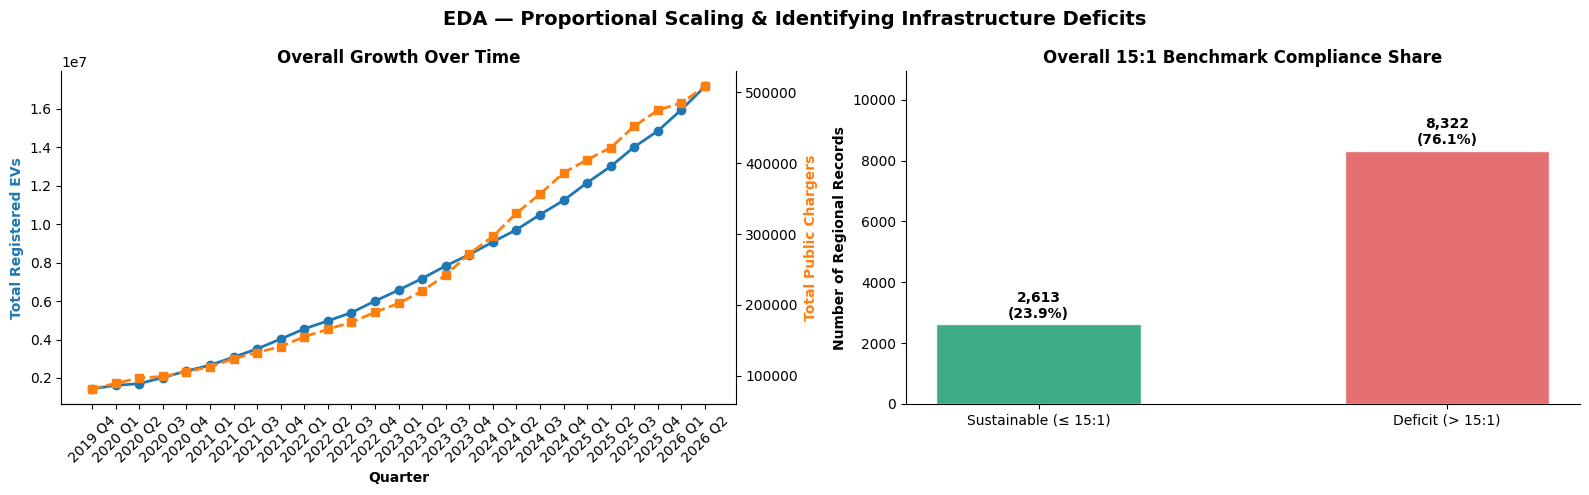

In [ ]:
section('EXPLORATORY DATA ANALYSIS')

df_core = df_core.sort_values(by=['ONS Code', 'Quarter']) #Groups up regions to display on chronological order
df_core['Total Chargers'] = df_core['Total Chargers'].fillna(0) #Fills in NaN values in Total Chargers

#Calculates EV-to-Charger ratio and deficit based of the 15:1 threshold
df_core['EV_Charger_Ratio'] = np.where(
    df_core['Total Chargers'] > 0, #Checks if region has 0 chargers
    df_core['Total EVs'] / df_core['Total Chargers'], #Divides electric vehicles against chargers row-by-row
    df_core['Total EVs']
)
df_core['Deficit_Status'] = np.where(df_core['EV_Charger_Ratio'] > 15, STATUS_NAMES[1], STATUS_NAMES[0])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('EDA — Proportional Scaling & Identifying Infrastructure Deficits', fontsize=14, fontweight='bold')

ax1 = axes[0]
quarterly_totals = df_core.groupby('Quarter')[['Total EVs', 'Total Chargers']].sum().reset_index()

ax1.plot(quarterly_totals['Quarter'], quarterly_totals['Total EVs'], label='Total EVs (Sum)', color='#1f77b4', marker='o', linewidth=2)
ax1.set_title('Overall Growth Over Time', fontweight='bold')
ax1.set_ylabel('Total Registered EVs', color='#1f77b4', fontweight='bold')
ax1.set_xlabel('Quarter', fontweight='bold')
ax1.tick_params(axis='x', rotation=45)
[ax1.spines[s].set_visible(False) for s in ['top', 'right']]

ax2 = ax1.twinx()
ax2.plot(quarterly_totals['Quarter'], quarterly_totals['Total Chargers'], label='Total Chargers (Sum)', color='#ff7f0e', marker='s', linewidth=2, linestyle='--')
ax2.set_ylabel('Total Public Chargers', color='#ff7f0e', fontweight='bold')
ax2.grid(False) # Prevent gridline clashing
[ax2.spines[s].set_visible(False) for s in ['top', 'left']]

ax3 = axes[1]
status_counts = df_core['Deficit_Status'].value_counts().reindex(STATUS_NAMES)
total_records = len(df_core)

bars = ax3.bar(status_counts.index, status_counts.values, color=STATUS_COLORS, alpha=0.85, edgecolor='white', width=0.5)

for bar in bars:
    height = bar.get_height()
    percentage = (height / total_records) * 100
    ax3.text(bar.get_x() + bar.get_width()/2, height + (total_records * 0.01),
            f'{height:,}\n({percentage:.1f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax3.set_title('Overall 15:1 Benchmark Compliance Share', fontweight='bold')
ax3.set_ylabel('Number of Regional Records', fontweight='bold')
ax3.set_ylim(0, total_records * 1) #Adds space for titlte
[ax3.spines[s].set_visible(False) for s in ['top', 'right']]

plt.tight_layout()
plt.show()

## Feature Engineering - 16 Nov

In [ ]:
section('FEATURE ENGINEERING')

#Groups sustainable and unsustainable quarters against 15 to 1 baseline
df_core['Deficit_Flag'] = np.where(df_core['EV_Charger_Ratio'] > 15, 1, 0) #'1' achieves the 15:1 baseline, '0' fails to achieve the baseline

df_core['Lag1_Chargers'] = df_core.groupby('ONS Code')['Total Chargers'].shift(1)
df_core['Lag2_Chargers'] = df_core.groupby('ONS Code')['Total Chargers'].shift(2)
df_core['Lag1_EVs'] = df_core.groupby('ONS Code')['Total EVs'].shift(1)
df_core['Lag2_EVs'] = df_core.groupby('ONS Code')['Total EVs'].shift(2)
df_core['Lag1_Ratio'] = df_core.groupby('ONS Code')['EV_Charger_Ratio'].shift(1)

feature_cols = ['Lag1_Chargers', 'Lag2_Chargers', 'Lag1_EVs', 'Lag2_EVs', 'Lag1_Ratio']
target_col = 'Deficit_Flag'

df_model = df_core.dropna(subset=feature_cols + [target_col]).copy() # Cleans NaN values to prevent crashes
X = df_model[feature_cols]
y = df_model[target_col]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED
)
display(df_model[['ONS Code', 'Quarter', 'Total Chargers', 'Lag1_Chargers', 'Lag2_Chargers', 'Deficit_Flag']].head(10))
display(df_model[['ONS Code', 'Quarter', 'Total Chargers', 'Lag1_Chargers', 'Lag2_Chargers', 'Deficit_Flag']].tail(10))


  FEATURE ENGINEERING


,ONS Code,Quarter,Total Chargers,Lag1_Chargers,Lag2_Chargers,Deficit_Flag
9726,E06000001,2020 Q2,6.0,5.0,5.0,1
9321,E06000001,2020 Q3,6.0,6.0,5.0,1
8916,E06000001,2020 Q4,6.0,6.0,6.0,1
8511,E06000001,2021 Q1,8.0,6.0,6.0,1
8106,E06000001,2021 Q2,9.0,8.0,6.0,1
7701,E06000001,2021 Q3,10.0,9.0,8.0,1
7296,E06000001,2021 Q4,11.0,10.0,9.0,1
6891,E06000001,2022 Q1,13.0,11.0,10.0,1
6486,E06000001,2022 Q2,12.0,13.0,11.0,1
6081,E06000001,2022 Q3,11.0,12.0,13.0,1


,ONS Code,Quarter,Total Chargers,Lag1_Chargers,Lag2_Chargers,Deficit_Flag
3982,W92000004,2024 Q1,2246.0,2061.0,1885.0,1
3577,W92000004,2024 Q2,2542.0,2246.0,2061.0,1
3172,W92000004,2024 Q3,2770.0,2542.0,2246.0,1
2767,W92000004,2024 Q4,3033.0,2770.0,2542.0,1
2362,W92000004,2025 Q1,3127.0,3033.0,2770.0,1
1957,W92000004,2025 Q2,3258.0,3127.0,3033.0,1
1552,W92000004,2025 Q3,3519.0,3258.0,3127.0,1
1147,W92000004,2025 Q4,3813.0,3519.0,3258.0,1
742,W92000004,2026 Q1,3850.0,3813.0,3519.0,1
337,W92000004,2026 Q2,3944.0,3850.0,3813.0,1


## Base Model Training

In [ ]:
section('BASE MODEL TRAINING (80/20 split)')

base_model_defs = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, C=1.0,
        class_weight='balanced', random_state=RANDOM_SEED),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=20,
        class_weight='balanced', random_state=RANDOM_SEED),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=10,
        class_weight='balanced', n_jobs=-1, random_state=RANDOM_SEED),
}

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
trained_models = {}
cv_scores = {}

for name, model_def in base_model_defs.items():
  model = copy.deepcopy(model_def)
  model.fit(X_train, y_train)
  trained_models[name] = model

  cv_f1 = cross_val_score(
            model, X_train, y_train,
            cv=cv5, scoring='f1', n_jobs=-1
  )
  cv_scores[name] = cv_f1
  print(f"Training {name:<19} ... CV F1 (Deficit): {cv_f1.mean():.4f} ± {cv_f1.std():.4f}")


  BASE MODEL TRAINING (80/20 split)
Training Logistic Regression ... CV F1 (Deficit): 0.9677 ± 0.0036
Training Decision Tree       ... CV F1 (Deficit): 0.9713 ± 0.0063
Training Random Forest       ... CV F1 (Deficit): 0.9784 ± 0.0028


## Evaluation on Held-Out Test Set

In [ ]:
section('EVALUATION ON TEST SET')

results = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    f1_w = f1_score(y_test, y_pred, average='weighted')
    f1_m = f1_score(y_test, y_pred, average='macro')
    roc_auc = roc_auc_score(y_test, y_prob)
    f1_deficit = f1_score(y_test, y_pred, pos_label=1)

    results[name] = {
        'y_pred': y_pred,
        'y_prob': y_prob,
        'Accuracy': acc,
        'F1_Weighted': f1_w,
        'F1_Macro': f1_m,
        'ROC_AUC': roc_auc,
        'F1_Deficit': f1_deficit
    }

    print(f"\n{name}")
    print(f"Accuracy      : {acc:.4f}")
    print(f"F1 Weighted   : {f1_w:.4f}")
    print(f"F1 Macro      : {f1_m:.4f}")
    print(f"ROC-AUC       : {roc_auc:.4f}")
    print(f"F1 (Deficit)  : {f1_deficit:.4f}\n")

    print(classification_report(y_test, y_pred, target_names=['Sustainable (≤15:1)', 'Deficit (>15:1)']))
    print("-" * 60)


  EVALUATION ON TEST SET

Logistic Regression
Accuracy      : 0.9541
F1 Weighted   : 0.9550
F1 Macro      : 0.9369
ROC-AUC       : 0.9876
F1 (Deficit)  : 0.9698

                     precision    recall  f1-score   support

Sustainable (≤15:1)       0.85      0.96      0.90       455
    Deficit (>15:1)       0.99      0.95      0.97      1570

           accuracy                           0.95      2025
          macro avg       0.92      0.96      0.94      2025
       weighted avg       0.96      0.95      0.96      2025

------------------------------------------------------------

Decision Tree
Accuracy      : 0.9640
F1 Weighted   : 0.9641
F1 Macro      : 0.9488
ROC-AUC       : 0.9885
F1 (Deficit)  : 0.9767

                     precision    recall  f1-score   support

Sustainable (≤15:1)       0.91      0.93      0.92       455
    Deficit (>15:1)       0.98      0.97      0.98      1570

           accuracy                           0.96      2025
          macro avg       0.94

## Plots — Base Models


  PLOTS - BASE MODELS


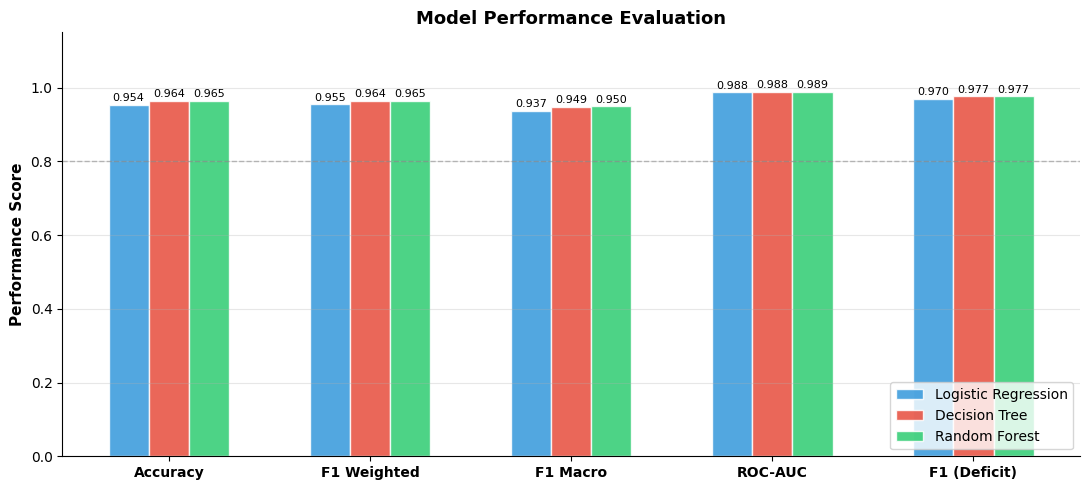

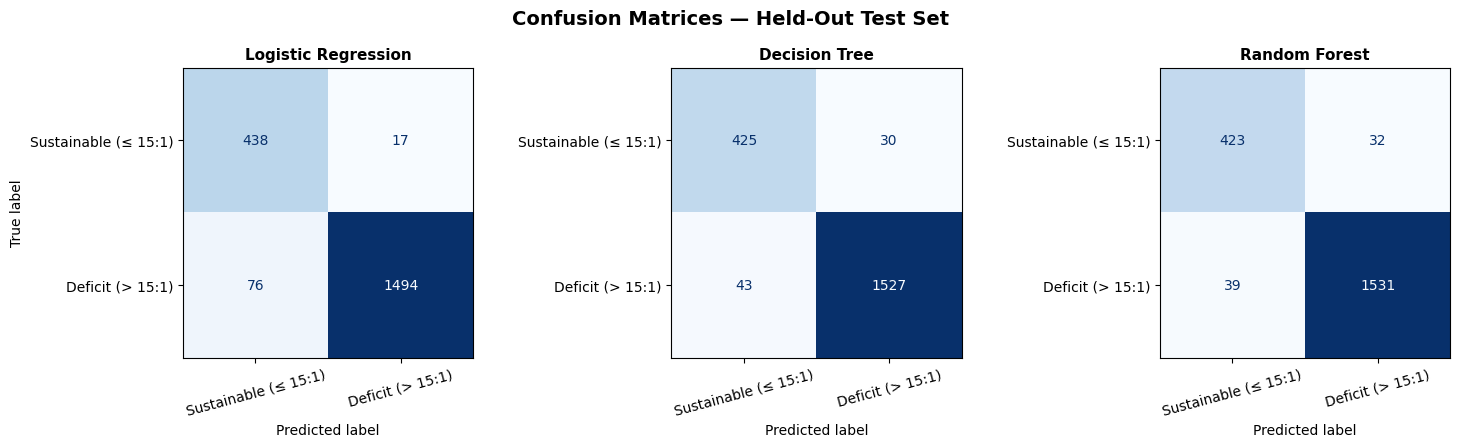

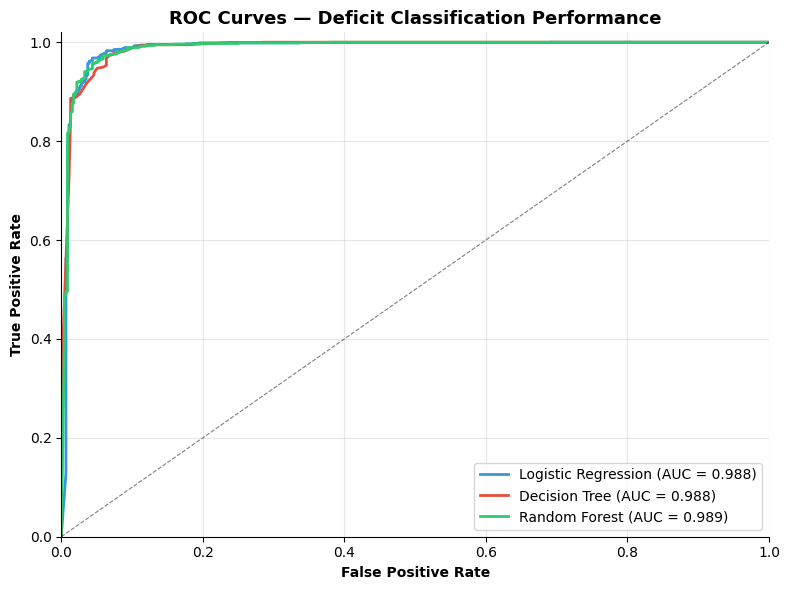

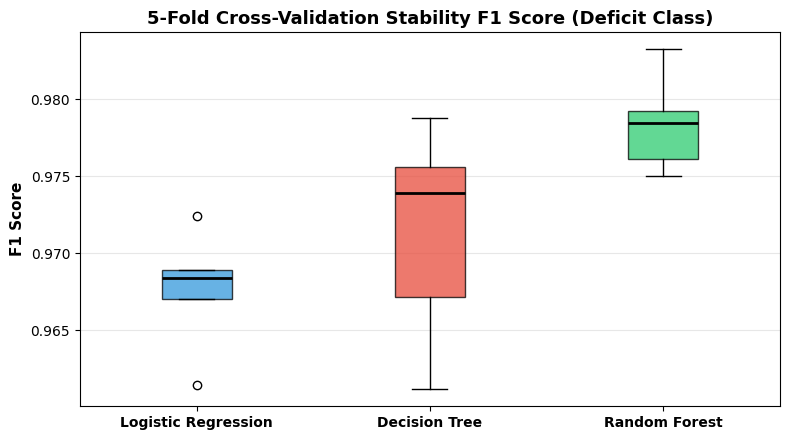

In [ ]:
bassection('PLOTS - BASE MODELS')
palette = ['#3498db', '#e74c3c', '#2ecc71']
model_names = ['Logistic Regression', 'Decision Tree', 'Random Forest']
class_labels = ['Sustainable (≤ 15:1)', 'Deficit (> 15:1)']

#Model Performance Evaluation
fig, ax = plt.subplots(figsize=(11, 5))
metrics_to_plot = ['Accuracy', 'F1_Weighted', 'F1_Macro', 'ROC_AUC', 'F1_Deficit']
metric_labels   = ['Accuracy', 'F1 Weighted', 'F1 Macro', 'ROC-AUC', 'F1 (Deficit)']
x = np.arange(len(metrics_to_plot)) #Labels locations on x-axis
width = 0.20

for i, (name, color) in enumerate(zip(model_names, palette)): #Applies palette to model names
    vals = [results[name][m] for m in metrics_to_plot]
    bars = ax.bar(x + i*width, vals, width, label=name, color=color, alpha=0.85, edgecolor='white')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.004,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x + width)
ax.set_xticklabels(metric_labels, fontsize=10, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.set_ylabel('Performance Score', fontsize=11, fontweight='bold')
ax.set_title('Model Performance Evaluation', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.axhline(y=0.8, color='gray', linestyle='--', alpha=0.5, linewidth=1)
ax.grid(axis='y', alpha=0.3)
[ax.spines[s].set_visible(False) for s in ['top', 'right']]
plt.tight_layout()
plt.show()

#Confusion Matrices Grid
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.suptitle('Confusion Matrices — Held-Out Test Set', fontsize=14, fontweight='bold')
for col_i, name in enumerate(model_names):
    ax = axes[col_i]
    cm = confusion_matrix(y_test, results[name]['y_pred'])
    ConfusionMatrixDisplay(cm, display_labels=class_labels).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontweight='bold', fontsize=11)
    ax.tick_params(axis='x', rotation=15)
    if col_i > 0:
        ax.set_ylabel('')
plt.tight_layout()
plt.show()

#ROC Curves
fig, ax = plt.subplots(figsize=(8, 6))
for name, color in zip(model_names, palette):
    res = results[name]
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    ax.plot(fpr, tpr, label=f'{name} (AUC = {res["ROC_AUC"]:.3f})', color=color, linewidth=2)
ax.plot([0, 1], [0, 1], 'k--', linewidth=0.8, alpha=0.5)
ax.set_title('ROC Curves — Deficit Classification Performance', fontweight='bold', fontsize=13)
ax.set_xlabel('False Positive Rate', fontweight='bold')
ax.set_ylabel('True Positive Rate', fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(alpha=0.3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
[ax.spines[s].set_visible(False) for s in ['top', 'right']]
plt.tight_layout()
plt.show()

#5-Fold Cross-Validation F1 Boxplot
fig, ax = plt.subplots(figsize=(8, 4.5))
cv_data = [cv_scores[n] for n in model_names]
bp = ax.boxplot(cv_data, tick_labels=model_names, patch_artist=True, medianprops=dict(color='black', linewidth=2))

for patch, color in zip(bp['boxes'], palette):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

ax.set_title('5-Fold Cross-Validation Stability F1 Score (Deficit Class)', fontsize=13, fontweight='bold')
ax.set_ylabel('F1 Score', fontsize=11, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.set_xticklabels(model_names, fontweight='bold')

plt.tight_layout()
plt.show()

## Full 10-Fold Cross-Validation

In [ ]:
section('FULL 10-FOLD CROSS-VALIDATION')
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_SEED)

cv_model_fns = {
    'Logistic Regression': lambda: LogisticRegression(
        max_iter=1000, C=1.0, class_weight='balanced', random_state=RANDOM_SEED),
    'Decision Tree': lambda: DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=20, class_weight='balanced', random_state=RANDOM_SEED),
    'Random Forest': lambda: RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=10,
        class_weight='balanced', n_jobs=-1, random_state=RANDOM_SEED),
}

cv_model_names = list(cv_model_fns.keys())
cv_palette = ['#3498db', '#e74c3c', '#2ecc71']

X_raw = X.values
y_all = y
full_cv = {}

print("Running 10-Fold Cross-Validation across dataset...")

for name, model_fn in cv_model_fns.items():
    fold_roc_te, fold_roc_tr, fold_f1 = [], [], []

    for tr_idx, te_idx in cv10.split(X_raw, y_all):
        X_tr_f, X_te_f = X_raw[tr_idx], X_raw[te_idx]
        y_tr_f = y_all.iloc[tr_idx]
        y_te_f = y_all.iloc[te_idx]

        # Proper practice: fit scaler only on the training fold to avoid data leakage
        sc_fold = StandardScaler()
        X_tr_fs = sc_fold.fit_transform(X_tr_f)
        X_te_fs = sc_fold.transform(X_te_f)

        m = model_fn()
        m.fit(X_tr_fs, y_tr_f)

        fold_roc_te.append(roc_auc_score(y_te_f, m.predict_proba(X_te_fs)[:, 1]))
        fold_roc_tr.append(roc_auc_score(y_tr_f, m.predict_proba(X_tr_fs)[:, 1]))
        fold_f1.append(f1_score(y_te_f, m.predict(X_te_fs)))

    full_cv[name] = {
        'test_roc' : np.array(fold_roc_te),
        'train_roc': np.array(fold_roc_tr),
        'test_f1'  : np.array(fold_f1),
    }

    gap = np.mean(fold_roc_tr) - np.mean(fold_roc_te)
    verdict = ('well generalised' if gap < 0.02 else
               'slight overfitting' if gap < 0.06 else 'overfitting')

    print(f'\n  Model: {name}')
    print(f'    Test  ROC-AUC : {np.mean(fold_roc_te):.4f} ± {np.std(fold_roc_te):.4f}')
    print(f'    Train ROC-AUC : {np.mean(fold_roc_tr):.4f} ± {np.std(fold_roc_tr):.4f}')
    print(f'    Test  F1      : {np.mean(fold_f1):.4f} ± {np.std(fold_f1):.4f}')
    print(f'    Gap           : {gap:.4f}  ({verdict})')


  FULL 10-FOLD CROSS-VALIDATION
Running 10-Fold Cross-Validation across dataset...

  Model: Logistic Regression
    Test  ROC-AUC : 0.9913 ± 0.0031
    Train ROC-AUC : 0.9913 ± 0.0005
    Test  F1      : 0.9092 ± 0.0073
    Gap           : 0.0000  (well generalised)

  Model: Decision Tree
    Test  ROC-AUC : 0.9878 ± 0.0037
    Train ROC-AUC : 0.9945 ± 0.0003
    Test  F1      : 0.9746 ± 0.0036
    Gap           : 0.0067  (well generalised)

  Model: Random Forest
    Test  ROC-AUC : 0.9917 ± 0.0029
    Train ROC-AUC : 0.9972 ± 0.0001
    Test  F1      : 0.9770 ± 0.0033
    Gap           : 0.0055  (well generalised)



  VISUALIZATIONS FOR 10-FOLD CROSS-VALIDATION


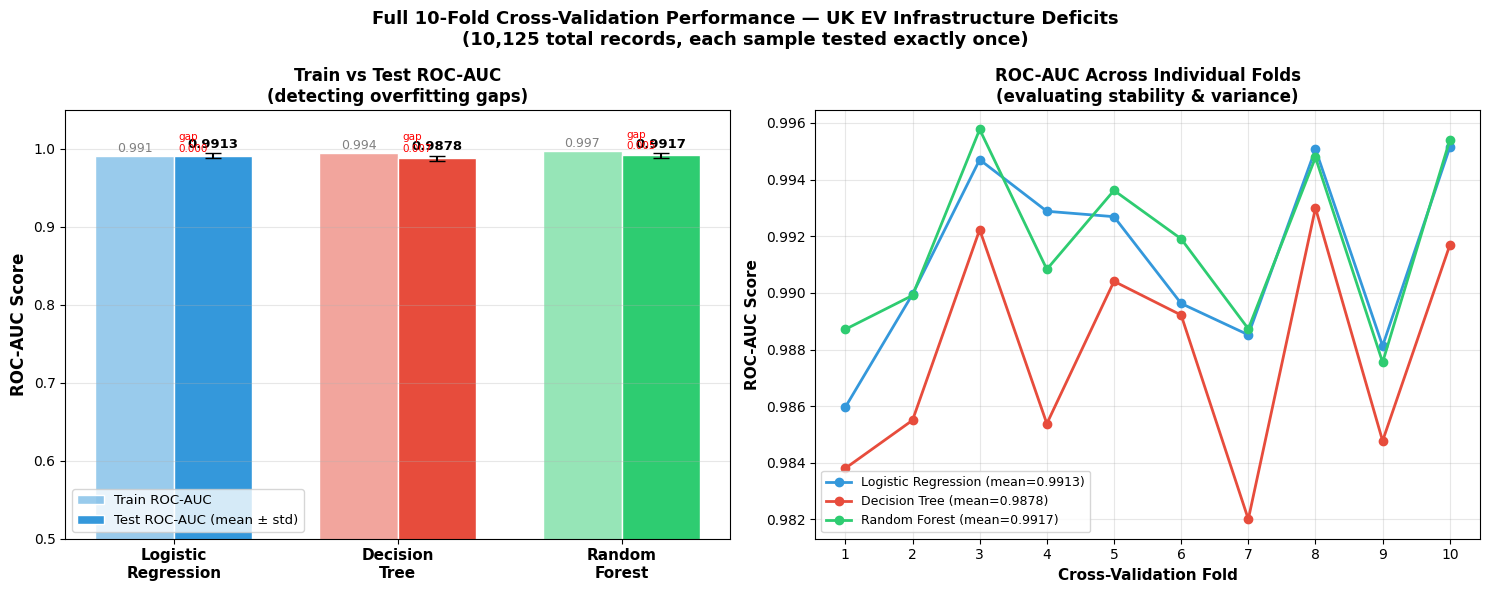

In [ ]:
section('VISUALIZATIONS FOR 10-FOLD CROSS-VALIDATION')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
n_total = len(X)
fig.suptitle(
    f'Full 10-Fold Cross-Validation Performance — UK EV Infrastructure Deficits\n'
    f'({n_total:,} total records, each sample tested exactly once)',
    fontsize=13, fontweight='bold')

tr_means = [full_cv[n]['train_roc'].mean() for n in cv_model_names]
te_means = [full_cv[n]['test_roc'].mean()  for n in cv_model_names]
te_stds  = [full_cv[n]['test_roc'].std()   for n in cv_model_names]
x = np.arange(len(cv_model_names)); w = 0.35

# Left Plot: Train vs Test ROC-AUC Gap
axes[0].bar(x - w/2, tr_means, w, label='Train ROC-AUC',
            color=[c + '80' for c in cv_palette], edgecolor='white')
axes[0].bar(x + w/2, te_means, w, yerr=te_stds,
            label='Test ROC-AUC (mean ± std)',
            color=cv_palette, capsize=6, edgecolor='white')
axes[0].set_xticks(x)
axes[0].set_xticklabels(
    ['Logistic\nRegression', 'Decision\nTree', 'Random\nForest'], fontsize=11, fontweight='bold')
axes[0].set_ylim(0.5, 1.05); axes[0].set_ylabel('ROC-AUC Score', fontsize=12, fontweight='bold')
axes[0].set_title('Train vs Test ROC-AUC\n(detecting overfitting gaps)', fontweight='bold')
axes[0].legend(fontsize=9.5); axes[0].grid(axis='y', alpha=0.3)

for i, (tm, te, ts) in enumerate(zip(tr_means, te_means, te_stds)):
    gap = tm - te
    axes[0].text(i - w/2, tm + 0.005, f'{tm:.3f}', ha='center', fontsize=9, color='gray')
    axes[0].text(i + w/2, te + ts + 0.007, f'{te:.4f}', ha='center', fontsize=9.5, fontweight='bold')
    axes[0].text(i + 0.02, (tm + te)/2 + 0.005,
                 f'gap\n{gap:.3f}', fontsize=7.5, color='red', ha='left')

# Right Plot: Fold-by-Fold Stability
for name, color in zip(cv_model_names, cv_palette):
    fold_scores = full_cv[name]['test_roc']
    axes[1].plot(range(1, 11), fold_scores, 'o-', color=color,
                 linewidth=2, markersize=6,
                 label=f'{name} (mean={fold_scores.mean():.4f})')
axes[1].set_xlabel('Cross-Validation Fold', fontsize=11, fontweight='bold')
axes[1].set_ylabel('ROC-AUC Score', fontsize=11, fontweight='bold')
axes[1].set_title('ROC-AUC Across Individual Folds\n(evaluating stability & variance)', fontweight='bold')
axes[1].legend(fontsize=9); axes[1].grid(alpha=0.3)
axes[1].set_xticks(range(1, 11))

plt.tight_layout()
plt.show()